## Import Library

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau

from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import drive

## Load Data

In [5]:
drive.mount('/content/drive')

BASE_PATH = "/content/drive/MyDrive/deepfake_dataset"

TRAIN_DIR = os.path.join(BASE_PATH, "train")
VAL_DIR   = os.path.join(BASE_PATH, "val")
TEST_DIR  = os.path.join(BASE_PATH, "test")

classes = ["real", "fake"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## EDA

In [7]:
def count_images(directory):
    return {
        cls: len(os.listdir(os.path.join(directory, cls)))
        for cls in classes
    }

df = pd.DataFrame({
    "train": count_images(TRAIN_DIR),
    "val": count_images(VAL_DIR),
    "test": count_images(TEST_DIR)
})

print(df)

      train  val  test
real    301  101    95
fake    301  101    89


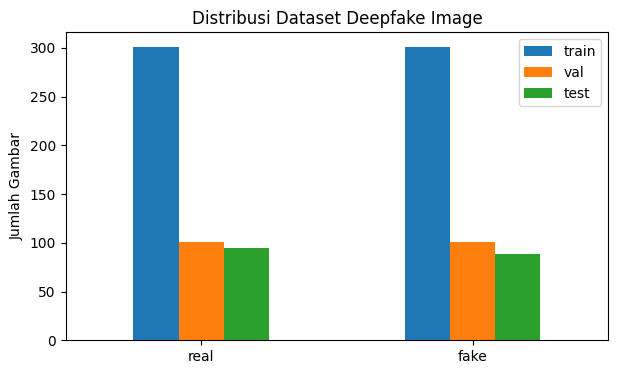

In [8]:
df.plot(kind="bar", figsize=(7,4))
plt.title("Distribusi Dataset Deepfake Image")
plt.ylabel("Jumlah Gambar")
plt.xticks(rotation=0)
plt.show()

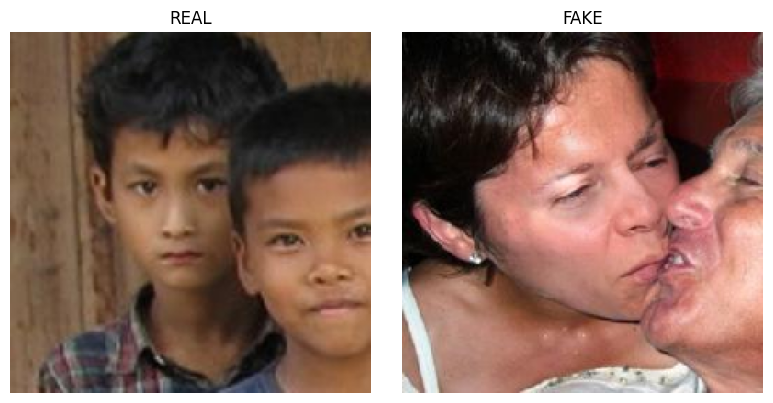

In [9]:
plt.figure(figsize=(8,4))

for i, cls in enumerate(classes):
    img_path = os.path.join(TRAIN_DIR, cls, os.listdir(os.path.join(TRAIN_DIR, cls))[0])
    img = load_img(img_path, target_size=(224,224))

    plt.subplot(1,2,i+1)
    plt.imshow(img)
    plt.title(cls.upper())
    plt.axis("off")

plt.tight_layout()
plt.show()

## Data Preprocessing

In [10]:
IMG_SIZE = (224,224)
BATCH_SIZE = 16

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [11]:
train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_gen = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 602 images belonging to 2 classes.
Found 202 images belonging to 2 classes.
Found 184 images belonging to 2 classes.


## Ekstraksi Fitur

In [12]:
feature_base = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet"
)

feature_model = Model(
    inputs=feature_base.input,
    outputs=GlobalAveragePooling2D()(feature_base.output)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [13]:
features = feature_model.predict(val_gen)
labels = val_gen.classes

print("Feature shape:", features.shape)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


13/13 ━━━━━━━━━━━━━━━━━━━━ 73s 6s/step
Feature shape: (202, 1280)


## PCA Visualization

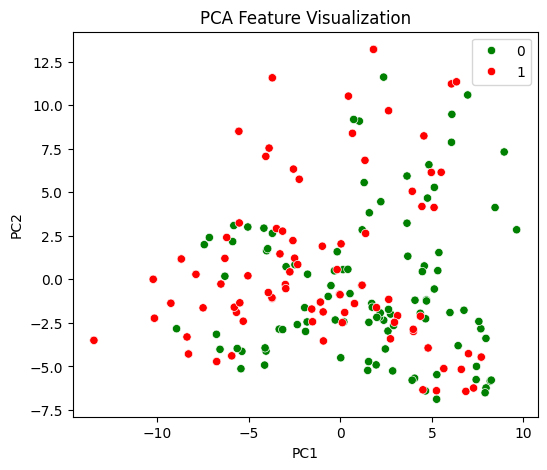

In [14]:
pca = PCA(n_components=2)
features_2d = pca.fit_transform(features)

plt.figure(figsize=(6,5))
sns.scatterplot(
    x=features_2d[:,0],
    y=features_2d[:,1],
    hue=labels,
    palette=["green", "red"]
)
plt.title("PCA Feature Visualization")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

## Modelling

In [15]:
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

In [16]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(64, activation="relu")(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

In [17]:
class StopAtHighAccuracy(Callback):
    def __init__(self, target_acc=0.90):
        super().__init__()
        self.target_acc = target_acc

    def on_epoch_end(self, epoch, logs=None):
        if logs.get("val_accuracy") >= self.target_acc:
            print("\nValidation accuracy > 90%, training dihentikan")
            self.model.stop_training = True


## Training

In [18]:
model.compile(
    optimizer=Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[
        StopAtHighAccuracy(0.90),
        EarlyStopping(patience=5, restore_best_weights=True)
    ]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 267s 7s/step - accuracy: 0.5847 - loss: 0.7432 - val_accuracy: 0.6485 - val_loss: 0.6827
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 36s 933ms/step - accuracy: 0.7316 - loss: 0.5433 - val_accuracy: 0.5594 - val_loss: 0.8393
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 37s 953ms/step - accuracy: 0.7633 - loss: 0.5308 - val_accuracy: 0.5644 - val_loss: 0.9827
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 37s 975ms/step - accuracy: 0.8685 - loss: 0.3238 - val_accuracy: 0.6337 - val_loss: 0.6971
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 36s 942ms/step - accuracy: 0.8380 - loss: 0.3487 - val_accuracy: 0.6139 - val_loss: 0.8153
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 37s 981ms/step - accuracy: 0.8589 - loss: 0.3275 - val_accuracy: 0.6436 - val_loss: 0.7557


## Fine Tuning

In [19]:
base_model.trainable = True

for layer in base_model.layers[:-40]:
    layer.trainable = False

In [20]:
model.compile(
    optimizer=Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=[
        StopAtHighAccuracy(0.90),
        ReduceLROnPlateau(patience=3)
    ]
)

Epoch 1/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.6317 - loss: 0.6767 - val_accuracy: 0.6634 - val_loss: 0.6714 - learning_rate: 1.0000e-04
Epoch 2/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.8705 - loss: 0.3207 - val_accuracy: 0.6832 - val_loss: 0.7751 - learning_rate: 1.0000e-04
Epoch 3/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9195 - loss: 0.2217 - val_accuracy: 0.7178 - val_loss: 0.7388 - learning_rate: 1.0000e-04
Epoch 4/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.9444 - loss: 0.1585 - val_accuracy: 0.6832 - val_loss: 1.0195 - learning_rate: 1.0000e-04
Epoch 5/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.9603 - loss: 0.1195 - val_accuracy: 0.6782 - val_loss: 1.0086 - learning_rate: 1.0000e-05
Epoch 6/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.9611 - loss: 0.1067 - val_accuracy: 0.6782 - val_loss: 1.0319 - learning_rate: 1.0000e-05
Epoch 7/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step - accuracy: 0.9759 - loss:

## Evaluasi

In [21]:
loss, acc = model.evaluate(test_gen)
print(f"Akurasi Test: {acc:.2%}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 62s 6s/step - accuracy: 0.7385 - loss: 0.6160
Akurasi Test: 77.72%


In [22]:
y_pred = (model.predict(test_gen) > 0.5).astype(int)

print(classification_report(
    test_gen.classes,
    y_pred,
    target_names=["Real", "Fake"]
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 947ms/step
              precision    recall  f1-score   support

        Real       0.81      0.71      0.75        89
        Fake       0.75      0.84      0.80        95

    accuracy                           0.78       184
   macro avg       0.78      0.77      0.78       184
weighted avg       0.78      0.78      0.78       184



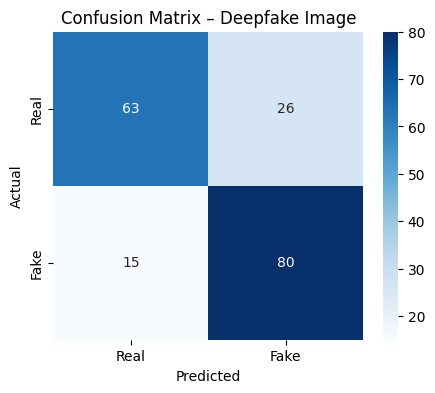

In [23]:
cm = confusion_matrix(test_gen.classes, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Deepfake Image")
plt.show()

In [24]:
model.save("model_comvis.h5")